# 06 - Wachstum und Zerfall

**Voraussetzungen:** [05_Exponential_Logarithmus_Funktionen](05_Exponential_Logarithmus_Funktionen.ipynb)

---

### Lernziele

Nach diesem Abschnitt kannst du:
- **Exponentielles Wachstum** und **exponentiellen Zerfall** modellieren
- Zwischen der **Basis-Form** $N(t) = N_0 \cdot a^t$ und der **e-Form** $N(t) = N_0 \cdot e^{\lambda t}$ umrechnen
- **Verdopplungszeit** und **Halbwertszeit** bestimmen
- **Begrenztes Wachstum** und **logistisches Wachstum** einordnen
- Wachstumsmodelle auf realistische Probleme anwenden

### 1. Exponentielles Wachstum und Zerfall

Ein Prozess heisst **exponentiell**, wenn die Änderungsrate proportional zum aktuellen Bestand ist.

**Basis-Form (Wachstumsfaktor):**

$$N(t) = N_0 \cdot a^t$$

| Symbol | Bedeutung |
|--------|-----------|
| $N_0$ | Anfangswert zum Zeitpunkt $t = 0$ |
| $a$ | Wachstumsfaktor pro Zeiteinheit |
| $t$ | Zeit |

| Fall | Bedingung | Verhalten |
|------|-----------|-----------|
| Wachstum | $a > 1$ | Bestand nimmt zu |
| Zerfall | $0 < a < 1$ | Bestand nimmt ab |

**e-Form (Wachstumsrate):**

$$N(t) = N_0 \cdot e^{\lambda t}$$

| Symbol | Bedeutung |
|--------|-----------|
| $\lambda > 0$ | Wachstumsrate → Zunahme |
| $\lambda < 0$ | Zerfallsrate → Abnahme |

**Umrechnung** zwischen den Formen:

$$a = e^{\lambda} \quad \Longleftrightarrow \quad \lambda = \ln(a)$$

Die e-Form ist in der Mathematik und Physik üblicher, weil sich $e^{\lambda t}$ leichter differenzieren lässt: $\frac{d}{dt} N_0 \, e^{\lambda t} = \lambda \, N_0 \, e^{\lambda t}$.

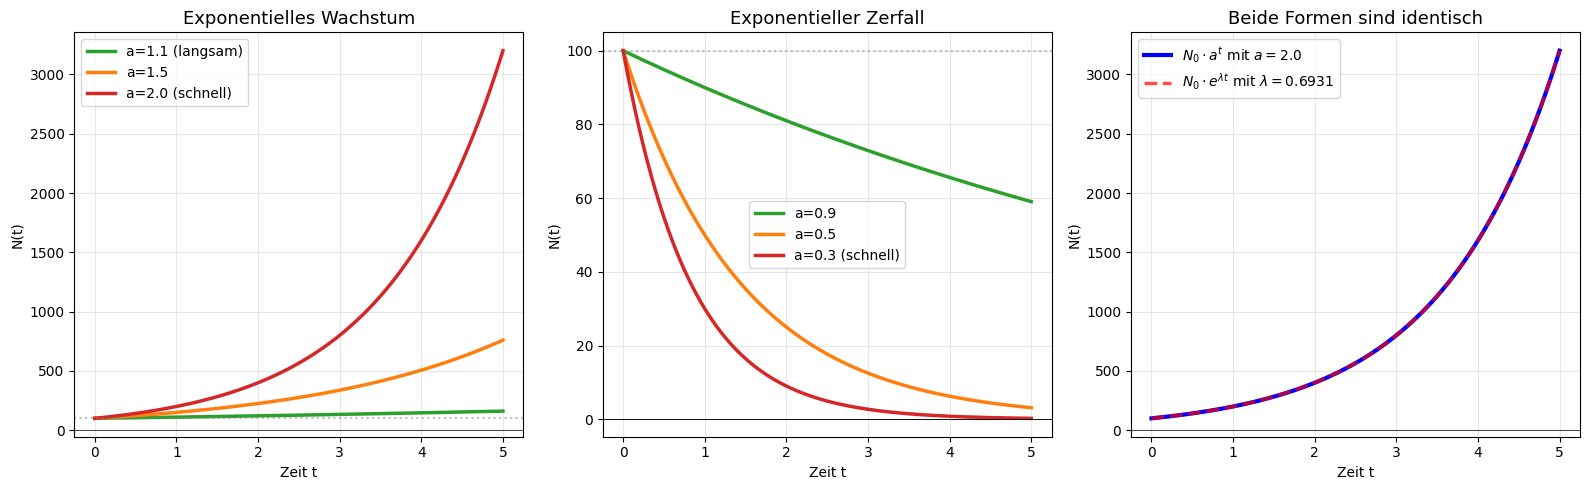

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# --- Exponentielles Wachstum und Zerfall ---

def visualisiere_wachstum_zerfall():
    """Vergleicht verschiedene Wachstums- und Zerfallsprozesse."""
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    t = np.linspace(0, 5, 300)

    # --- Links: Verschiedene Wachstumsfaktoren ---
    ax = axes[0]
    N0 = 100
    for a, label, farbe in [(1.1, 'a=1.1 (langsam)', '#2ca02c'),
                             (1.5, 'a=1.5', '#ff7f0e'),
                             (2.0, 'a=2.0 (schnell)', '#d62728')]:
        ax.plot(t, N0 * a**t, linewidth=2.5, color=farbe, label=label)
    ax.axhline(N0, color='gray', linestyle=':', alpha=0.5)
    ax.set_title("Exponentielles Wachstum", fontsize=13)
    ax.set_xlabel("Zeit t")
    ax.set_ylabel("N(t)")
    ax.legend()
    ax.grid(True, alpha=0.3)

    # --- Mitte: Zerfall ---
    ax = axes[1]
    for a, label, farbe in [(0.9, 'a=0.9', '#2ca02c'),
                             (0.5, 'a=0.5', '#ff7f0e'),
                             (0.3, 'a=0.3 (schnell)', '#d62728')]:
        ax.plot(t, N0 * a**t, linewidth=2.5, color=farbe, label=label)
    ax.axhline(N0, color='gray', linestyle=':', alpha=0.5)
    ax.axhline(0, color='black', linewidth=0.5)
    ax.set_title("Exponentieller Zerfall", fontsize=13)
    ax.set_xlabel("Zeit t")
    ax.set_ylabel("N(t)")
    ax.legend()
    ax.grid(True, alpha=0.3)

    # --- Rechts: Basis-Form vs e-Form (identisch) ---
    ax = axes[2]
    a = 2.0
    lam = np.log(a)
    ax.plot(t, N0 * a**t, 'b-', linewidth=3, label=f"$N_0 \\cdot a^t$ mit $a={a}$")
    ax.plot(t, N0 * np.exp(lam * t), 'r--', linewidth=2.5, alpha=0.7,
            label=f"$N_0 \\cdot e^{{\\lambda t}}$ mit $\\lambda={lam:.4f}$")
    ax.set_title("Beide Formen sind identisch", fontsize=13)
    ax.set_xlabel("Zeit t")
    ax.set_ylabel("N(t)")
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)

    for ax in axes:
        ax.axhline(0, color='black', linewidth=0.5)

    plt.tight_layout()
    plt.show()

visualisiere_wachstum_zerfall()

### 2. Verdopplungszeit und Halbwertszeit

Zwei zentrale Kenngrößen für exponentielle Prozesse:

**Verdopplungszeit** $t_2$ (bei Wachstum, $\lambda > 0$):

$$N(t_2) = 2 \, N_0 \quad \Rightarrow \quad e^{\lambda t_2} = 2 \quad \Rightarrow \quad t_2 = \frac{\ln 2}{\lambda}$$

**Halbwertszeit** $t_{1/2}$ (bei Zerfall, $\lambda < 0$):

$$N(t_{1/2}) = \frac{N_0}{2} \quad \Rightarrow \quad e^{\lambda \, t_{1/2}} = \frac{1}{2} \quad \Rightarrow \quad t_{1/2} = \frac{\ln 2}{|\lambda|}$$

In der Basis-Form:

$$t_2 = \frac{\ln 2}{\ln a} \qquad \text{bzw.} \qquad t_{1/2} = \frac{\ln 2}{\ln(1/a)} = \frac{-\ln 2}{\ln a}$$

| Kenngrößen | Formel (e-Form) | Formel (Basis-Form) |
|------------|-----------------|---------------------|
| Verdopplungszeit | $t_2 = \frac{\ln 2}{\lambda}$ | $t_2 = \frac{\ln 2}{\ln a}$ |
| Halbwertszeit | $t_{1/2} = \frac{\ln 2}{\lvert\lambda\rvert}$ | $t_{1/2} = \frac{\ln 2}{\ln(1/a)}$ |
| Prozentuale Änderung/ZE | $p = e^{\lambda} - 1$ | $p = a - 1$ |

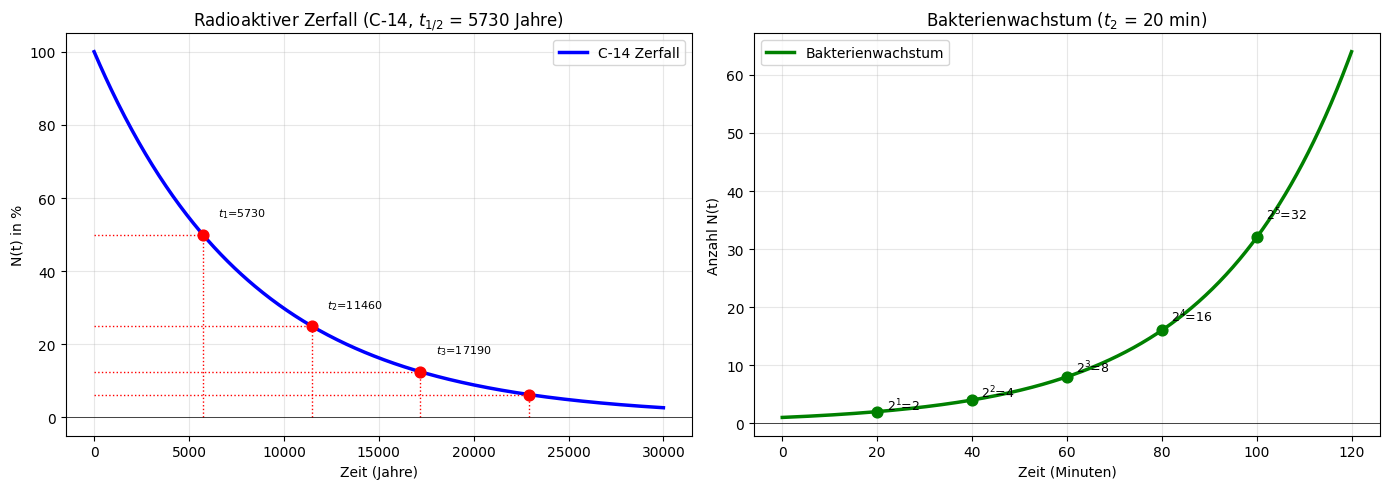

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# --- Halbwertszeit und Verdopplungszeit ---

def visualisiere_halbwerts_verdopplungszeit():
    """Zeigt Halbwertszeit (Zerfall) und Verdopplungszeit (Wachstum) graphisch."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # --- Links: Halbwertszeit (Radioaktiver Zerfall) ---
    ax = axes[0]
    t_half = 5730  # C-14 in Jahren
    lam = -np.log(2) / t_half
    t = np.linspace(0, 30000, 500)
    N0 = 100
    N = N0 * np.exp(lam * t)

    ax.plot(t, N, 'b-', linewidth=2.5, label="C-14 Zerfall")
    # Halbwertszeiten einzeichnen
    for k in range(1, 5):
        t_k = k * t_half
        N_k = N0 / (2**k)
        ax.plot([t_k, t_k], [0, N_k], 'r:', linewidth=1)
        ax.plot([0, t_k], [N_k, N_k], 'r:', linewidth=1)
        ax.scatter(t_k, N_k, color='red', s=60, zorder=5)
        if k <= 3:
            ax.annotate(f"$t_{{{k}}}$={t_k}", xy=(t_k, N_k),
                       xytext=(t_k+800, N_k+5), fontsize=8)

    ax.set_title(f"Radioaktiver Zerfall (C-14, $t_{{1/2}}$ = {t_half} Jahre)", fontsize=12)
    ax.set_xlabel("Zeit (Jahre)")
    ax.set_ylabel("N(t) in %")
    ax.legend()
    ax.grid(True, alpha=0.3)

    # --- Rechts: Verdopplungszeit (Bakterien) ---
    ax = axes[1]
    t_dbl = 20  # Minuten
    lam_w = np.log(2) / t_dbl
    t2 = np.linspace(0, 120, 500)
    N0_b = 1
    N_b = N0_b * np.exp(lam_w * t2)

    ax.plot(t2, N_b, 'g-', linewidth=2.5, label="Bakterienwachstum")
    for k in range(1, 6):
        t_k = k * t_dbl
        N_k = N0_b * 2**k
        ax.scatter(t_k, N_k, color='green', s=60, zorder=5)
        ax.annotate(f"$2^{k}$={N_k:.0f}", xy=(t_k, N_k),
                   xytext=(t_k+2, N_k*1.1), fontsize=9)

    ax.set_title(f"Bakterienwachstum ($t_2$ = {t_dbl} min)", fontsize=12)
    ax.set_xlabel("Zeit (Minuten)")
    ax.set_ylabel("Anzahl N(t)")
    ax.legend()
    ax.grid(True, alpha=0.3)

    for ax in axes:
        ax.axhline(0, color='black', linewidth=0.5)

    plt.tight_layout()
    plt.show()

visualisiere_halbwerts_verdopplungszeit()

### 3. Weitere Wachstumsmodelle

Exponentielles Wachstum ist unbegrenzt - in der Realität gibt es oft eine **Kapazitätsgrenze**.

---

#### Begrenztes Wachstum (Sättigungsmodell)

$$N(t) = S - (S - N_0) \cdot e^{-k t} \qquad (k > 0)$$

Der Bestand nähert sich der **Schranke** $S$ an, ohne sie zu überschreiten. Die Änderungsrate wird kleiner, je näher $N$ an $S$ liegt.

*Beispiele:* Aufwärmen eines Körpers, Ladevorgang eines Kondensators, Lernen einer Fertigkeit.

---

#### Logistisches Wachstum

$$N(t) = \frac{K}{1 + \left(\frac{K - N_0}{N_0}\right) \cdot e^{-r t}}$$

| Symbol | Bedeutung |
|--------|-----------|
| $K$ | Kapazitätsgrenze (Carrying Capacity) |
| $r$ | Wachstumsrate |
| $N_0$ | Anfangswert |

Der Graph hat eine typische **S-Form** (Sigmoidkurve):
1. Anfangs nahezu exponentielles Wachstum
2. Wendepunkt bei $N = K/2$ - maximale Wachstumsgeschwindigkeit
3. Sättigung: $N(t) \to K$ für $t \to \infty$

*Beispiele:* Populationsdynamik, Verbreitung von Epidemien, Marktdurchdringung.

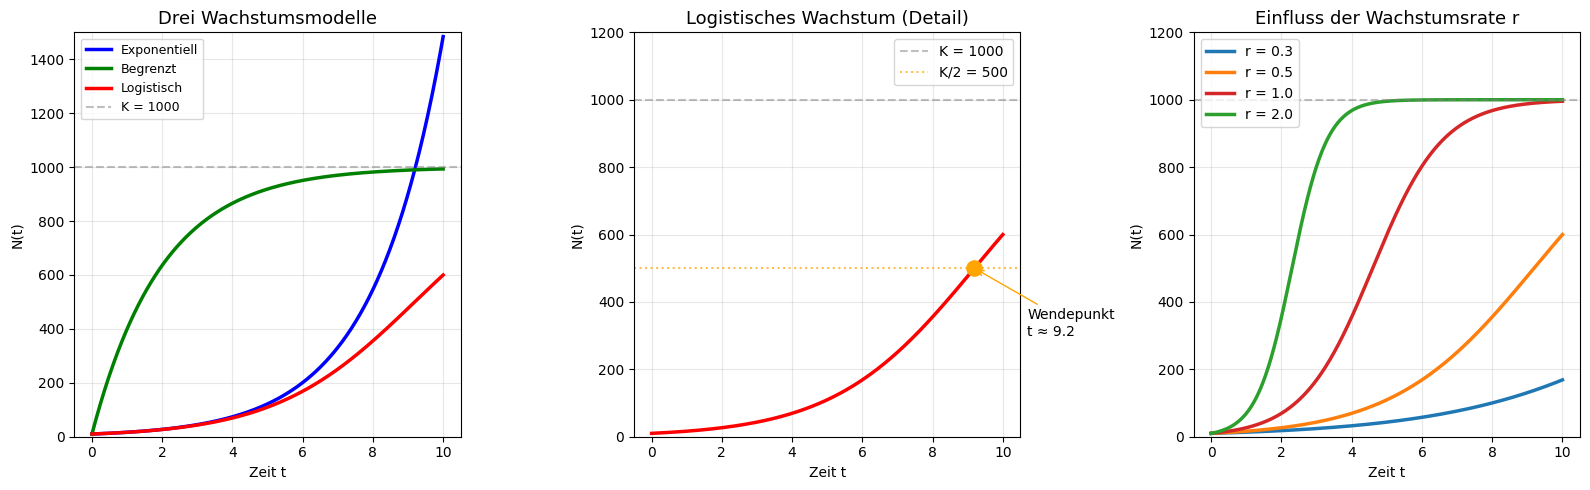

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# --- Vergleich der Wachstumsmodelle ---

def visualisiere_wachstumsmodelle():
    """Vergleicht exponentielles, begrenztes und logistisches Wachstum."""
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    t = np.linspace(0, 10, 500)
    N0 = 10
    K = 1000  # Kapazitätsgrenze

    # --- Links: Alle drei Modelle im Vergleich ---
    ax = axes[0]
    r = 0.5

    # Exponentiell
    N_exp = N0 * np.exp(r * t)
    ax.plot(t, N_exp, 'b-', linewidth=2.5, label="Exponentiell")

    # Begrenzt
    N_begr = K - (K - N0) * np.exp(-r * t)
    ax.plot(t, N_begr, 'g-', linewidth=2.5, label="Begrenzt")

    # Logistisch
    N_log = K / (1 + ((K - N0)/N0) * np.exp(-r * t))
    ax.plot(t, N_log, 'r-', linewidth=2.5, label="Logistisch")

    ax.axhline(K, color='gray', linestyle='--', alpha=0.5, label=f"K = {K}")
    ax.set_title("Drei Wachstumsmodelle", fontsize=13)
    ax.set_xlabel("Zeit t")
    ax.set_ylabel("N(t)")
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.set_ylim(0, 1500)

    # --- Mitte: Logistisches Wachstum (S-Kurve, Details) ---
    ax = axes[1]
    ax.plot(t, N_log, 'r-', linewidth=2.5)
    ax.axhline(K, color='gray', linestyle='--', alpha=0.5, label=f"K = {K}")
    ax.axhline(K/2, color='orange', linestyle=':', alpha=0.7, label=f"K/2 = {K/2:.0f}")
    # Wendepunkt
    t_wend = np.log((K - N0)/N0) / r
    ax.scatter(t_wend, K/2, color='orange', s=120, zorder=5)
    ax.annotate(f"Wendepunkt\nt ≈ {t_wend:.1f}", xy=(t_wend, K/2),
               xytext=(t_wend+1.5, K/2-200), fontsize=10,
               arrowprops=dict(arrowstyle='->', color='orange'))
    ax.set_title("Logistisches Wachstum (Detail)", fontsize=13)
    ax.set_xlabel("Zeit t")
    ax.set_ylabel("N(t)")
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)
    ax.set_ylim(0, 1200)

    # --- Rechts: Verschiedene r-Werte ---
    ax = axes[2]
    for r_val, farbe in [(0.3, '#1f77b4'), (0.5, '#ff7f0e'), (1.0, '#d62728'), (2.0, '#2ca02c')]:
        N = K / (1 + ((K - N0)/N0) * np.exp(-r_val * t))
        ax.plot(t, N, linewidth=2.5, color=farbe, label=f"r = {r_val}")
    ax.axhline(K, color='gray', linestyle='--', alpha=0.5)
    ax.set_title("Einfluss der Wachstumsrate r", fontsize=13)
    ax.set_xlabel("Zeit t")
    ax.set_ylabel("N(t)")
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)
    ax.set_ylim(0, 1200)

    for ax in axes:
        ax.axhline(0, color='black', linewidth=0.5)

    plt.tight_layout()
    plt.show()

visualisiere_wachstumsmodelle()

### 4. Anwendungsbeispiele

| Anwendung | Modell | Typische Parameter |
|-----------|--------|--------------------|
| Radioaktiver Zerfall | $N(t) = N_0 \cdot e^{-\lambda t}$ | C-14: $t_{1/2} = 5730$ Jahre |
| Bakterienwachstum | $N(t) = N_0 \cdot 2^{t/t_2}$ | E. coli: $t_2 \approx 20$ min |
| Zinseszins | $K(t) = K_0 \cdot (1 + p/100)^t$ | Jahreszins $p$ in % |
| Stetige Verzinsung | $K(t) = K_0 \cdot e^{rt}$ | $r = \ln(1 + p/100)$ |
| Abkühlung (Newton) | $T(t) = T_U + (T_0 - T_U) \cdot e^{-kt}$ | Begrenztes Modell |
| Bevölkerung | Logistisch | Kapazitätsgrenze $K$ |

**Modellwahl:**  
- **Unbeschränktes** exponentielles Modell: geeignet für kurze Zeiträume  
- **Begrenztes** Modell: wenn ein Sättigungswert bekannt ist  
- **Logistisches** Modell: wenn zunächst exponentielles Wachstum vorliegt, das sich dann verlangsamt

In [4]:
import numpy as np

# --- Anwendungsbeispiel: Zinseszins ---

print("=== Zinseszins-Vergleich ===")
print()

K0 = 1000  # Anfangskapital in Euro
p = 5      # Zinssatz in %
jahre = [5, 10, 20, 30]

print(f"Anfangskapital: {K0} €, Zinssatz: {p}%\n")
print(f"{'Jahre':<10} {'Jährlich':<15} {'Stetig':<15}")
print("-" * 40)
for t in jahre:
    K_jaehrlich = K0 * (1 + p/100)**t
    K_stetig = K0 * np.exp(np.log(1 + p/100) * t)
    print(f"{t:<10} {K_jaehrlich:<15.2f} {K_stetig:<15.2f}")

print()
print("=== Radioaktiver Zerfall (C-14) ===")
print()
t_half = 5730
lam = np.log(2) / t_half
print(f"Halbwertszeit: {t_half} Jahre")
print(f"Zerfallsrate λ = {lam:.6f} pro Jahr")
print(f"Nach {t_half} Jahren: {100 * np.exp(-lam * t_half):.1f}% übrig")
print(f"Nach {2*t_half} Jahren: {100 * np.exp(-lam * 2*t_half):.1f}% übrig")
print(f"Nach {3*t_half} Jahren: {100 * np.exp(-lam * 3*t_half):.1f}% übrig")

=== Zinseszins-Vergleich ===

Anfangskapital: 1000 €, Zinssatz: 5%

Jahre      Jährlich        Stetig         
----------------------------------------
5          1276.28         1276.28        
10         1628.89         1628.89        
20         2653.30         2653.30        
30         4321.94         4321.94        

=== Radioaktiver Zerfall (C-14) ===

Halbwertszeit: 5730 Jahre
Zerfallsrate λ = 0.000121 pro Jahr
Nach 5730 Jahren: 50.0% übrig
Nach 11460 Jahren: 25.0% übrig
Nach 17190 Jahren: 12.5% übrig


---

## Verständnis-Check

**Aufgabe 1:** Eine Bakterienkultur verdoppelt sich alle 30 Minuten. Zu Beginn sind 500 Bakterien vorhanden.  
a) Stelle die Wachstumsfunktion in der Basis-Form auf.  
b) Wie viele Bakterien sind nach 3 Stunden vorhanden?

**Aufgabe 2:** Ein radioaktiver Stoff hat eine Halbwertszeit von 8 Tagen. Bestimme die Zerfallsrate $\lambda$ und berechne, nach wie vielen Tagen noch 10% der Ausgangssubstanz übrig sind.

**Aufgabe 3:** Du legst 5000 € zu 3,5% Jahreszins an. Berechne das Kapital nach 15 Jahren.

**Aufgabe 4:** Eine Population wächst logistisch mit $K = 10\,000$, $N_0 = 100$, $r = 0{,}4$. Bestimme den Wendepunkt (Zeitpunkt und Populationsgröße).

### Lösungen

<details>
<summary>Lösung Aufgabe 1</summary>

a) $N(t) = 500 \cdot 2^{t/0{,}5} = 500 \cdot 2^{2t}$ (mit $t$ in Stunden)

Alternativ: $N(t) = 500 \cdot 2^{t/30}$ (mit $t$ in Minuten)

b) $N(3) = 500 \cdot 2^{6} = 500 \cdot 64 = 32\,000$
</details>

<details>
<summary>Lösung Aufgabe 2</summary>

$\lambda = \frac{\ln 2}{t_{1/2}} = \frac{\ln 2}{8} \approx 0{,}0866$ pro Tag

$0{,}1 = e^{-\lambda t} \Rightarrow t = \frac{-\ln(0{,}1)}{\lambda} = \frac{\ln 10}{\ln 2 / 8} = \frac{8 \ln 10}{\ln 2} \approx 26{,}6$ Tage
</details>

<details>
<summary>Lösung Aufgabe 3</summary>

$K(15) = 5000 \cdot 1{,}035^{15} = 5000 \cdot 1{,}6753 \approx 8376{,}49$ €
</details>

<details>
<summary>Lösung Aufgabe 4</summary>

Der Wendepunkt liegt bei $N = K/2 = 5000$.

Zeitpunkt: $\frac{K}{2} = \frac{K}{1 + \frac{K - N_0}{N_0} e^{-rt}}$

$\Rightarrow e^{-rt} = \frac{N_0}{K - N_0} \Rightarrow t = \frac{1}{r} \ln\left(\frac{K - N_0}{N_0}\right) = \frac{1}{0{,}4} \ln\left(\frac{9900}{100}\right) = 2{,}5 \cdot \ln(99) \approx 11{,}5$
</details>

---

## Zusammenfassung

| Thema | Kernaussage |
|-------|-------------|
| **Exp. Wachstum** | $N(t) = N_0 \cdot a^t$ mit $a > 1$, oder $N_0 \cdot e^{\lambda t}$ mit $\lambda > 0$ |
| **Exp. Zerfall** | $a < 1$ bzw. $\lambda < 0$ |
| **Umrechnung** | $a = e^{\lambda}$, $\lambda = \ln(a)$ |
| **Verdopplungszeit** | $t_2 = \frac{\ln 2}{\lambda}$ |
| **Halbwertszeit** | $t_{1/2} = \frac{\ln 2}{\lvert\lambda\rvert}$ |
| **Begrenztes Wachstum** | $N(t) = S - (S-N_0) \, e^{-kt}$ - nähert sich Schranke $S$ |
| **Logistisches Wachstum** | S-Kurve mit Kapazitätsgrenze $K$, Wendepunkt bei $K/2$ |

> **Nächster Schritt:** Funktionsmanipulationen (Verschiebung, Streckung, Spiegelung) → 07_Funktionsmanipulationen

---

## Glossar

| Deutsch | Englisch |
|---------|----------|
| Exponentielles Wachstum | Exponential growth |
| Exponentieller Zerfall | Exponential decay |
| Halbwertszeit | Half-life |
| Verdopplungszeit | Doubling time |
| Wachstumsfaktor | Growth factor |
| Wachstumsrate | Growth rate |
| Begrenztes Wachstum | Limited/bounded growth |
| Logistisches Wachstum | Logistic growth |
| Kapazitätsgrenze | Carrying capacity |
| Wendepunkt | Inflection point |